In [1]:
# prediction: For small B, the matmul will be memory bound, so seconds will roughly stay the same while TFLOP grows. Once the operation becaus FLOPs bound, seconds will start going up while TFLOP increases, so TFLOP/s will flatten out


In [1]:
import torch

start = torch.cuda.Event(enable_timing=True)
end = torch.cuda.Event(enable_timing=True)

mat2 = torch.randn(4096, 4096, device="cuda")
tflopsPerSecs = {}

for B in [1, 8, 64, 512]:
  mat1 = torch.randn(B, 4096, device="cuda")

  # warmup
  for _ in range(10):
      torch.matmul(mat1, mat2)
  torch.cuda.synchronize()

  start.record()
  # average over 100 attempts
  for _ in range(100):
    y = torch.matmul(mat1, mat2)
  end.record()
  torch.cuda.synchronize() # makes sure the GPU has finished all its work, otherwise the matmul or end.record() may not have finished

  ms = start.elapsed_time(end) / 100
  tflopsPerSec = 2 * B * 4096 * 4096 / (ms * 1e-3) / 1e12
  tflopsPerSecs[B] = tflopsPerSec



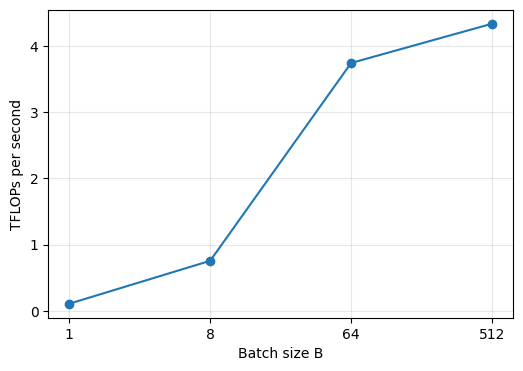

In [2]:
import matplotlib.pyplot as plt

xs = list(tflopsPerSecs.keys())
ys = list(tflopsPerSecs.values())

plt.figure(figsize=(6, 4))
plt.plot(xs, ys, marker="o")
plt.xscale("log", base=2)        # B values are spread out, so use a log scale
plt.xticks(xs, [str(b) for b in xs])
plt.xlabel("Batch size B")
plt.ylabel("TFLOPs per second")
plt.grid(True, which="both", alpha=0.3)
plt.show()